# 04 · Modelo base lineal sobre los retornos del WTI

Mismo modelo del cuaderno `Linear_Model_Baseline`: regresión lineal **directa y multisalida** resuelta con la ecuación normal.
Con los últimos **K** retornos del WTI predice los **H** siguientes.

| Tramo | Uso en este notebook |
|---|---|
| **Train (2010-2018)** | validación cruzada de ventana expansiva para elegir K, y ajuste final de W |
| **Validación (2019)** | evaluación fuera de muestra del modelo ya ajustado (no cambia K) |
| **Test (2020-2026)** | **cerrado hasta la sección 6**: se abre una sola vez, con `permitir_test=True` |

El modelo es una referencia: cualquier modelo posterior (GARCH, LSTM, TimeGAN) debe compararse con él y con el pronóstico "cero".

In [3]:
import sys
from pathlib import Path

# La raíz del proyecto es la carpeta que contiene `src/` (funciona se ejecute desde la raíz o desde notebooks/)
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib

from src import config as cfg
from src.preprocessing import cargar
from src.linear_baseline import (K_fold, create_sequences, normal_equation, predict, calculate_rmse,
                                 RMSE_CV, RMSE_CV_referencia, RMSE_CV_search_K,
                                 evaluar_segmento, rmse_por_ventana, reconstruir_vector, pronostico_futuro,
                                 r2_fuera_de_muestra, graficar_train_test_prediccion, graficar_precio_prediccion)

In [4]:
importlib.reload(cfg)

<module 'src.config' from 'c:\\Users\\ASUS\\Desktop\\Maestria IA USFQ\\TESIS\\DESARROLLO TESIS\\src\\config.py'>

## 1. Datos: retornos del WTI en train y validación

In [5]:
y_train = cargar("retornos", "train")[cfg.target]
y_val = cargar("retornos", "val")[cfg.target]

print("train:", y_train.index.min().date(), "->", y_train.index.max().date(), len(y_train), "| nulos:", y_train.isna().sum())
print("val:  ", y_val.index.min().date(), "->", y_val.index.max().date(), len(y_val), "| nulos:", y_val.isna().sum())

train: 2010-01-05 -> 2018-12-31 2259 | nulos: 0
val:   2019-01-02 -> 2019-12-31 252 | nulos: 0


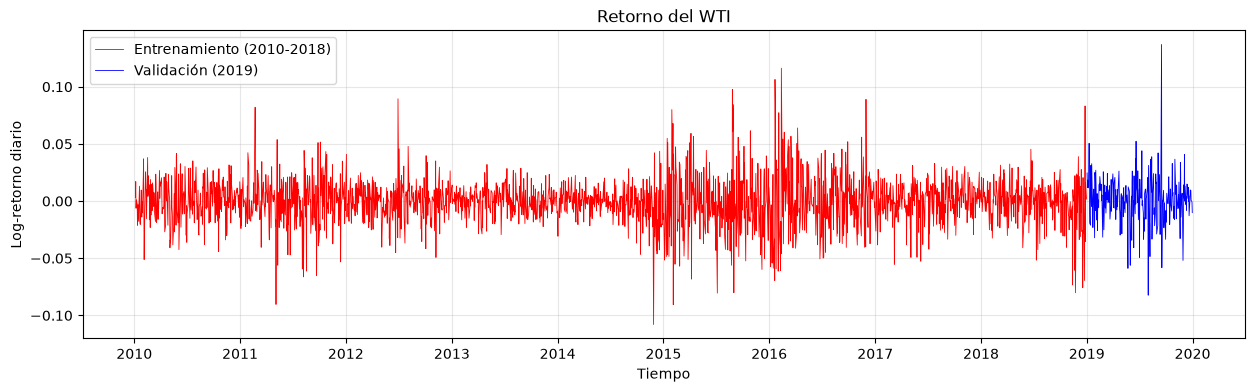

In [6]:
fig, ax = plt.subplots(figsize=(15, 4))
_ = ax.plot(y_train, color="r", lw=0.6, label="Entrenamiento (2010-2018)")
_ = ax.plot(y_val, color="b", lw=0.6, label="Validación (2019)")
_ = ax.set_xlabel("Tiempo"); ax.set_ylabel("Log-retorno diario")
_ = ax.set_title("Retorno del WTI"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 2. Validación cruzada de ventana expansiva (solo train)

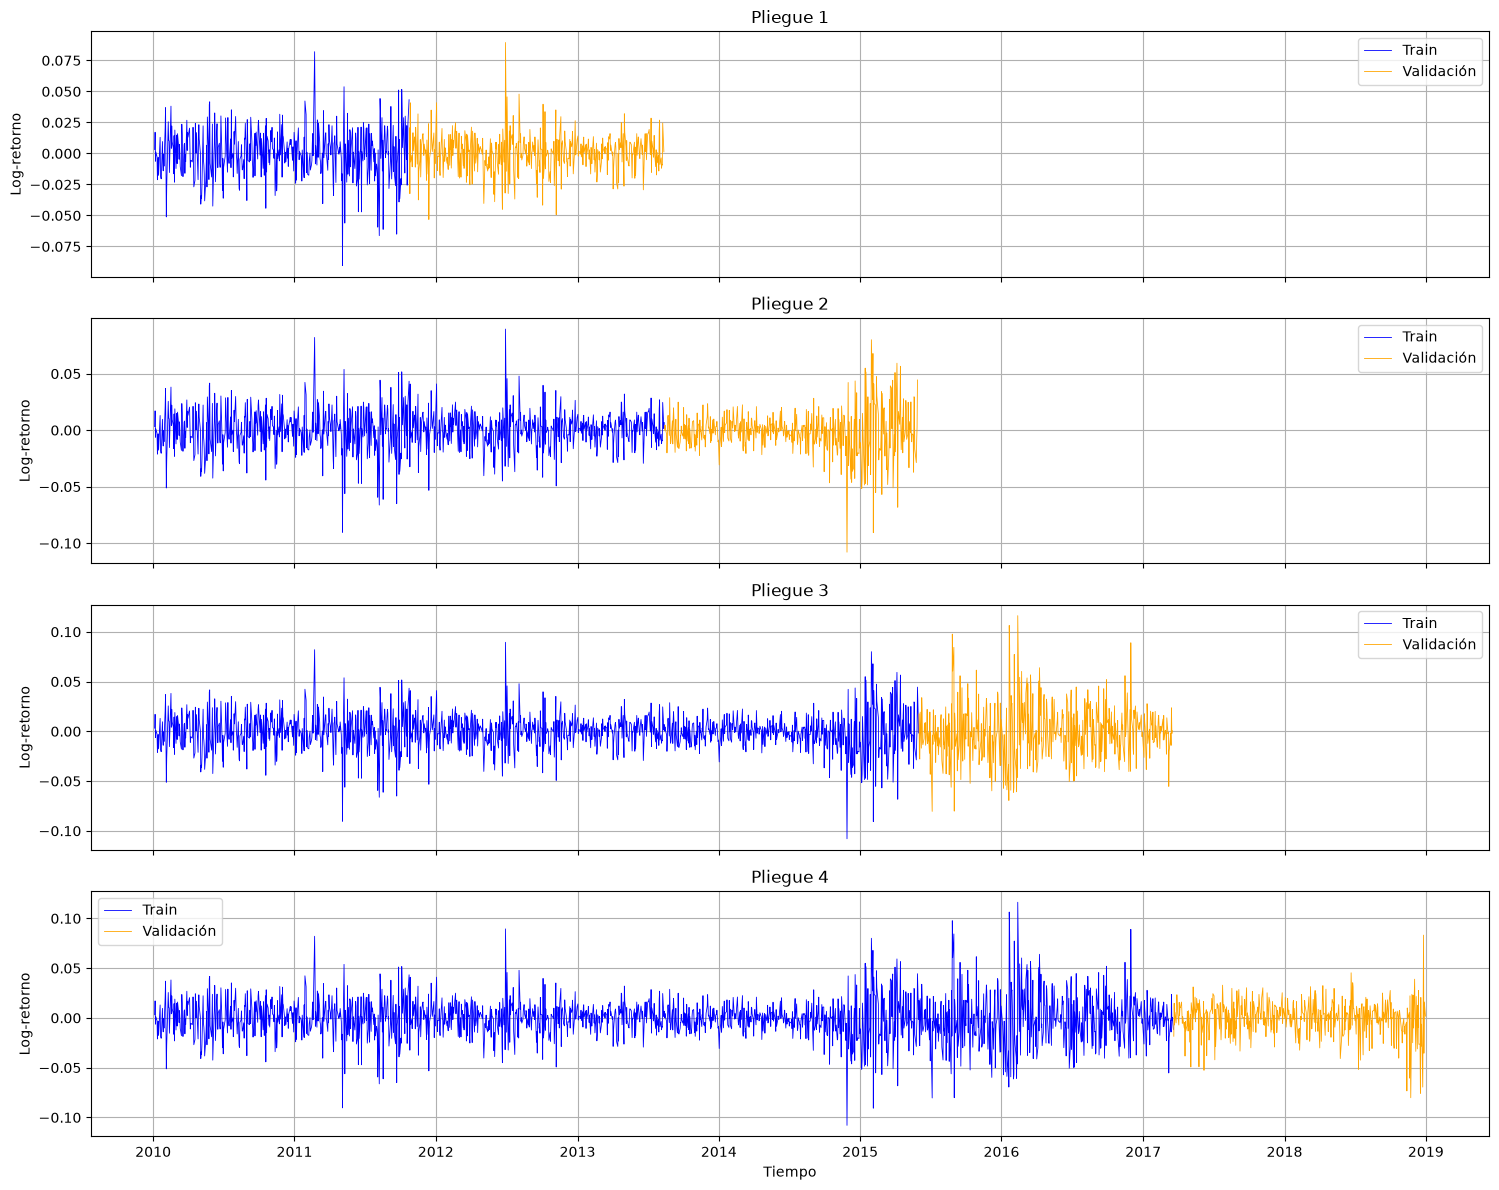

In [7]:
n_splits = 4
data_train_lst, data_validation_lst = K_fold(y_train, n_splits)
n_splits = len(data_train_lst)

fig, axs = plt.subplots(n_splits, 1, figsize=(15, 3 * n_splits), sharex=True)
for i in range(n_splits):
    axs[i].plot(data_train_lst[i], label="Train", color="blue", lw=0.6)
    axs[i].plot(data_validation_lst[i], label="Validación", color="orange", lw=0.6)
    axs[i].set_title(f"Pliegue {i + 1}")
    axs[i].set_ylabel("Log-retorno")
    axs[i].legend(); axs[i].grid(True)
plt.xlabel("Tiempo")
plt.tight_layout()
plt.show()

## 3. Ventanas, ecuación normal y RMSE en un pliegue (K = 1, H = 1)

In [8]:
steps_back = 1
steps_ahead = 1
X_train, Y_train = create_sequences(data_train_lst[0], steps_back, steps_ahead)
X_val, Y_val = create_sequences(data_validation_lst[0], steps_back, steps_ahead)
print(X_train.shape, Y_train.shape, X_val.shape, Y_val.shape)

(454, 1) (454, 1) (450, 1) (450, 1)


In [9]:
W_hat = normal_equation(X_train, Y_train)
W_hat       # fila 0: intercepto; resto: peso de cada retorno rezagado

array([[0.00023314],
       [0.05826129]])

In [10]:
Y_hat_train = predict(X_train, W_hat)
Y_hat_val = predict(X_val, W_hat)

rmse_train = calculate_rmse(Y_train, Y_hat_train)
rmse_val = calculate_rmse(Y_val, Y_hat_val)
rmse_cero = calculate_rmse(Y_val, np.zeros_like(Y_val))     # referencia: predecir siempre 0
print(f"RMSE train pliegue 1:       {rmse_train:.6f}")
print(f"RMSE validación pliegue 1:  {rmse_val:.6f}")
print(f"RMSE 'cero' en validación:  {rmse_cero:.6f}")

RMSE train pliegue 1:       0.019953
RMSE validación pliegue 1:  0.015285
RMSE 'cero' en validación:  0.015154


## 4. Elección de K por validación cruzada (solo train)

H es el horizonte de predicción. Mientras no se confirme con el tutor (`cfg.H_GRID`), aquí se fija uno para elegir K.
Para retornos diarios la comparación relevante es contra el pronóstico "cero".

El K con menor RMSE de validación es 3 (RMSE: 0.020209)


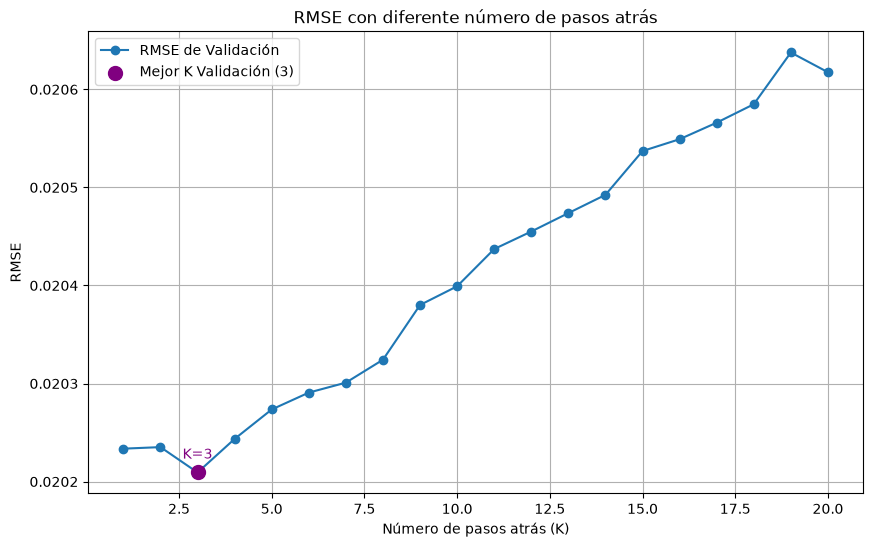

RMSE 'cero' (promedio de los pliegues): 0.020241


In [11]:
H = 1                       # horizonte; cambiar para otro valor de cfg.H_GRID
K_values = cfg.k_grid      # 1..20

best_k, rmse_tr_k, rmse_va_k = RMSE_CV_search_K(
    k_values=K_values, steps_ahead=H, training_dataset=y_train, n_splits=n_splits, plot="Validation")
print(f"RMSE 'cero' (promedio de los pliegues): {RMSE_CV_referencia(H, y_train, n_splits):.6f}")

In [12]:
pd.DataFrame({"K": K_values, "RMSE_train_cv": rmse_tr_k, "RMSE_val_cv": rmse_va_k}).set_index("K").round(6).T

K,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
RMSE_train_cv,0.019304,0.019298,0.019300,0.019305,0.019308,0.019303,0.019307,0.019306,0.019289,0.019285,0.019283,0.019281,0.019275,0.019280,0.019270,0.019264,0.019268,0.019267,0.019241,0.019192
RMSE_val_cv,0.020234,0.020235,0.020209,0.020244,0.020274,0.020291,0.020301,0.020324,0.020380,0.020399,0.020437,0.020455,0.020474,0.020492,0.020537,0.020549,0.020566,0.020585,0.020638,0.020617


In [13]:
# Mejor K para cada horizonte propuesto (solo con train)
filas = []
for h in cfg.h_grid:
    k_h, _, va_h = RMSE_CV_search_K(K_values, h, y_train, n_splits, plot=None, verbose=False)
    filas.append({"H": h, "mejor_K": k_h, "RMSE_val_cv": min(va_h),
                  "RMSE_cero_cv": RMSE_CV_referencia(h, y_train, n_splits)})
pd.DataFrame(filas).set_index("H").round(6)

,mejor_K,RMSE_val_cv,RMSE_cero_cv
H,,,
1,3,0.020209,0.020241
5,1,0.020222,0.020213
10,1,0.020161,0.020144
21,1,0.020148,0.020128
63,1,0.020106,0.020081


## 5. Validación (2019): modelo ajustado con todo train

Se ajusta W con **todo train** y el K elegido, y se evalúa en 2019. Las primeras K entradas de 2019 se toman del final de train
(`con_prefijo`), de modo que cada predicción de 2019 tiene sus K datos de entrada. **No se vuelve a elegir K con esto.**

In [14]:
X_tr, Y_tr = create_sequences(y_train, best_k, H)
W_final = normal_equation(X_tr, Y_tr)
mu_train = y_train.mean()

rmse_tr = calculate_rmse(Y_tr, predict(X_tr, W_final))
res_val = evaluar_segmento(y_train, y_val, W_final, best_k, H, mu_train)

print(f"K = {best_k}, H = {H}")
print(f"RMSE train:                  {rmse_tr:.6f}")
print(f"RMSE validación (modelo):    {res_val['RMSE_modelo']:.6f}")
print(f"RMSE validación (cero):      {res_val['RMSE_cero']:.6f}")
print(f"RMSE validación (media tr.): {res_val['RMSE_media_train']:.6f}")
print(f"ventanas válidas: {res_val['n_ventanas']}  |  descartadas por NaN: {res_val['n_descartadas']}")

K = 3, H = 1
RMSE train:                  0.020539
RMSE validación (modelo):    0.021289
RMSE validación (cero):      0.021267
RMSE validación (media tr.): 0.021283
ventanas válidas: 252  |  descartadas por NaN: 0


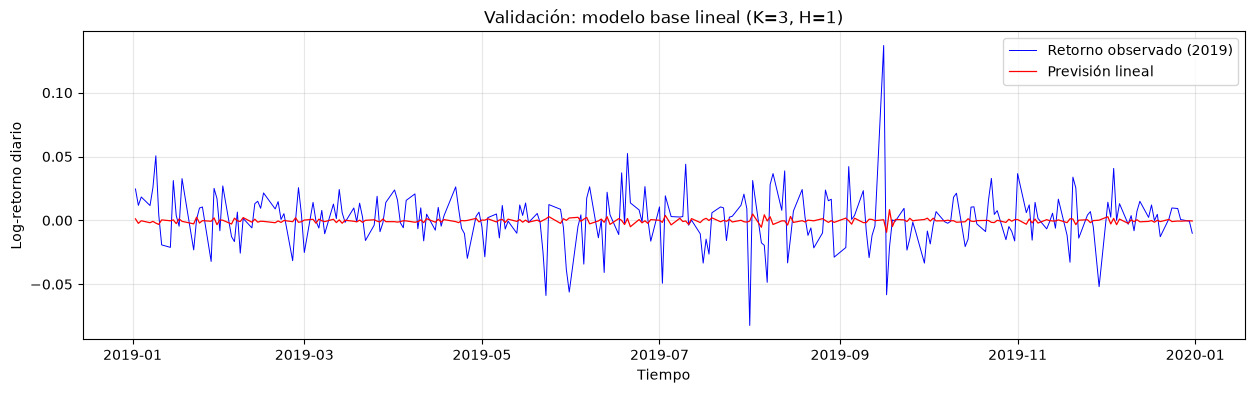

In [15]:
pred_val = reconstruir_vector(res_val["Y_hat"], y_val.index)

fig, ax = plt.subplots(figsize=(15, 4))
_ = ax.plot(y_val, color="b", lw=0.7, label="Retorno observado (2019)")
_ = ax.plot(pred_val, color="r", lw=0.9, label="Previsión lineal")
_ = ax.set_xlabel("Tiempo"); ax.set_ylabel("Log-retorno diario")
_ = ax.set_title(f"Validación: modelo base lineal (K={best_k}, H={H})"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 6. Test (2020 en adelante) — se abre una sola vez

A partir de aquí se usa el test, con el modelo **ya fijado** (K y W de la sección 5). El prefijo de entrada de la primera predicción
de 2020 son los últimos K días de 2019. En el WTI faltan los retornos del 20 y 21/04/2020 (precio negativo): las ventanas que los
contienen como entrada o como salida se descartan del RMSE y se cuentan aparte.

In [16]:
y_test = cargar("retornos", "test", permitir_test=True)[cfg.target]
print("test:", y_test.index.min().date(), "->", y_test.index.max().date(), len(y_test), "| nulos:", y_test.isna().sum())
print("fechas sin retorno:", [d.date() for d in y_test.index[y_test.isna()]])

test: 2020-01-02 -> 2026-10-20 1709 | nulos: 2
fechas sin retorno: [datetime.date(2020, 4, 20), datetime.date(2020, 4, 21)]


In [17]:
res_test = evaluar_segmento(y_val, y_test, W_final, best_k, H, mu_train)

print(f"RMSE test (modelo):    {res_test['RMSE_modelo']:.6f}")
print(f"RMSE test (cero):      {res_test['RMSE_cero']:.6f}")
print(f"RMSE test (media tr.): {res_test['RMSE_media_train']:.6f}")
print(f"ventanas válidas: {res_test['n_ventanas']}  |  descartadas por NaN: {res_test['n_descartadas']}")

RMSE test (modelo):    0.031595
RMSE test (cero):      0.031492
RMSE test (media tr.): 0.031496
ventanas válidas: 1704  |  descartadas por NaN: 5


In [18]:
# RMSE por sub-ventana del test (cfg.VENTANAS_TEST): COVID, recuperación, 2022, calma, 2026
rmse_por_ventana(res_test, cfg.ventanas_test, mu_train).round(6)

,ventanas_validas,descartadas_por_NaN,RMSE_modelo,RMSE_cero,RMSE_media_train
ventana,,,,,
covid,248,5,0.054504,0.054423,0.054420
rec_2021,252,0,0.022399,0.022405,0.022426
rob_2022,251,0,0.030704,0.030466,0.030469
calma_23_25,752,0,0.019920,0.019870,0.019866
rec_2026,201,0,0.038814,0.038570,0.038590


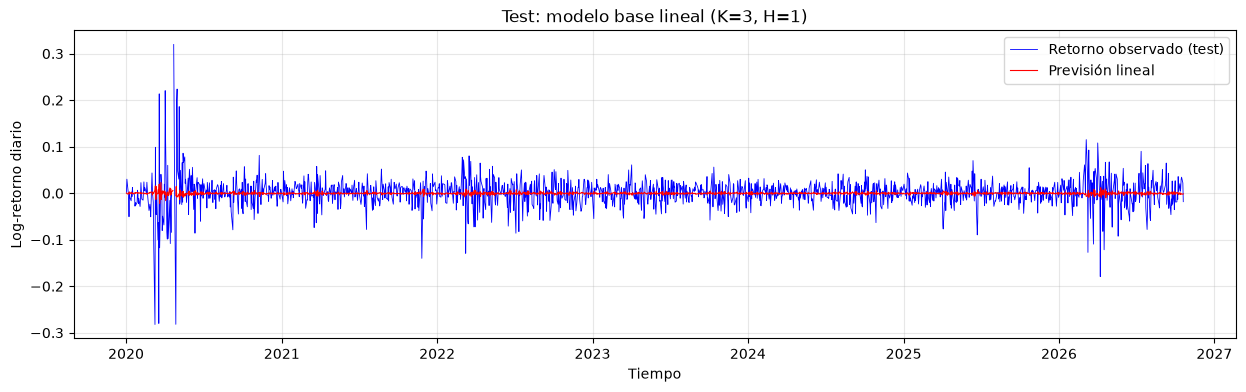

In [19]:
pred_test = reconstruir_vector(res_test["Y_hat"], y_test.index)

fig, ax = plt.subplots(figsize=(15, 4))
_ = ax.plot(y_test, color="b", lw=0.6, label="Retorno observado (test)")
_ = ax.plot(pred_test, color="r", lw=0.8, label="Previsión lineal")
_ = ax.set_xlabel("Tiempo"); ax.set_ylabel("Log-retorno diario")
_ = ax.set_title(f"Test: modelo base lineal (K={best_k}, H={H})"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

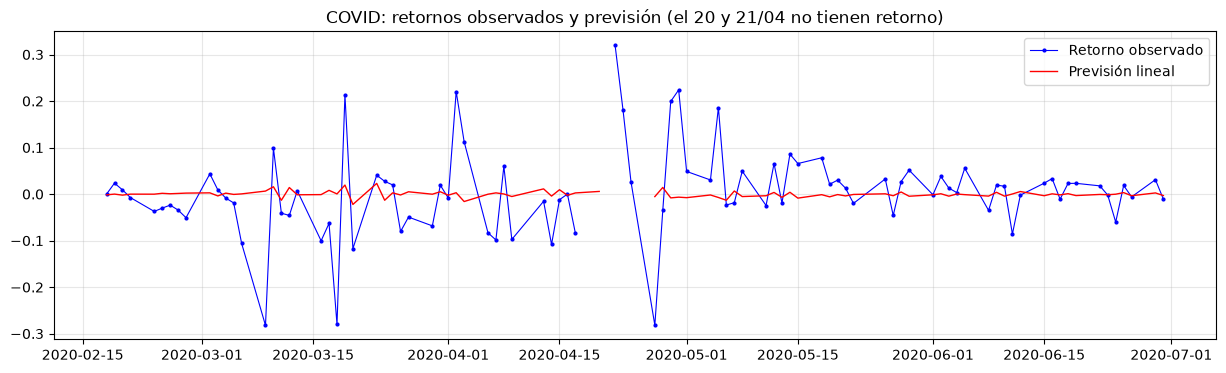

In [20]:
# Zoom en el evento COVID (feb-jun 2020)
a, b = "2020-02-15", "2020-06-30"
fig, ax = plt.subplots(figsize=(15, 4))
_ = ax.plot(y_test.loc[a:b], color="b", marker="o", ms=2, lw=0.8, label="Retorno observado")
_ = ax.plot(pred_test.loc[a:b], color="r", lw=1.0, label="Previsión lineal")
_ = ax.set_title("COVID: retornos observados y previsión (el 20 y 21/04 no tienen retorno)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

In [21]:
# Pronóstico de los H días siguientes al último dato (como en el cuaderno original)
pronostico_futuro(y_test.dropna(), W_final, best_k)

2026-10-21    0.000666
Freq: B, Name: Predicho, dtype: float64

In [22]:
resumen = pd.DataFrame({
    "RMSE_modelo": [res_val["RMSE_modelo"], res_test["RMSE_modelo"]],
    "RMSE_cero": [res_val["RMSE_cero"], res_test["RMSE_cero"]],
    "RMSE_media_train": [res_val["RMSE_media_train"], res_test["RMSE_media_train"]],
}, index=["validación 2019", "test 2020-2026"])
resumen["R2_OS_vs_cero"] = [r2_fuera_de_muestra(a, b) for a, b in zip(resumen["RMSE_modelo"], resumen["RMSE_cero"])]
print("Coeficientes W (fila 0: intercepto; luego, rezagos 1..K):", np.round(W_final.ravel(), 4))
resumen.round(6)

Coeficientes W (fila 0: intercepto; luego, rezagos 1..K): [-0.0003 -0.0294  0.0335 -0.0674]


,RMSE_modelo,RMSE_cero,RMSE_media_train,R2_OS_vs_cero
validación 2019,0.021289,0.021267,0.021283,-0.002065
test 2020-2026,0.031595,0.031492,0.031496,-0.006551


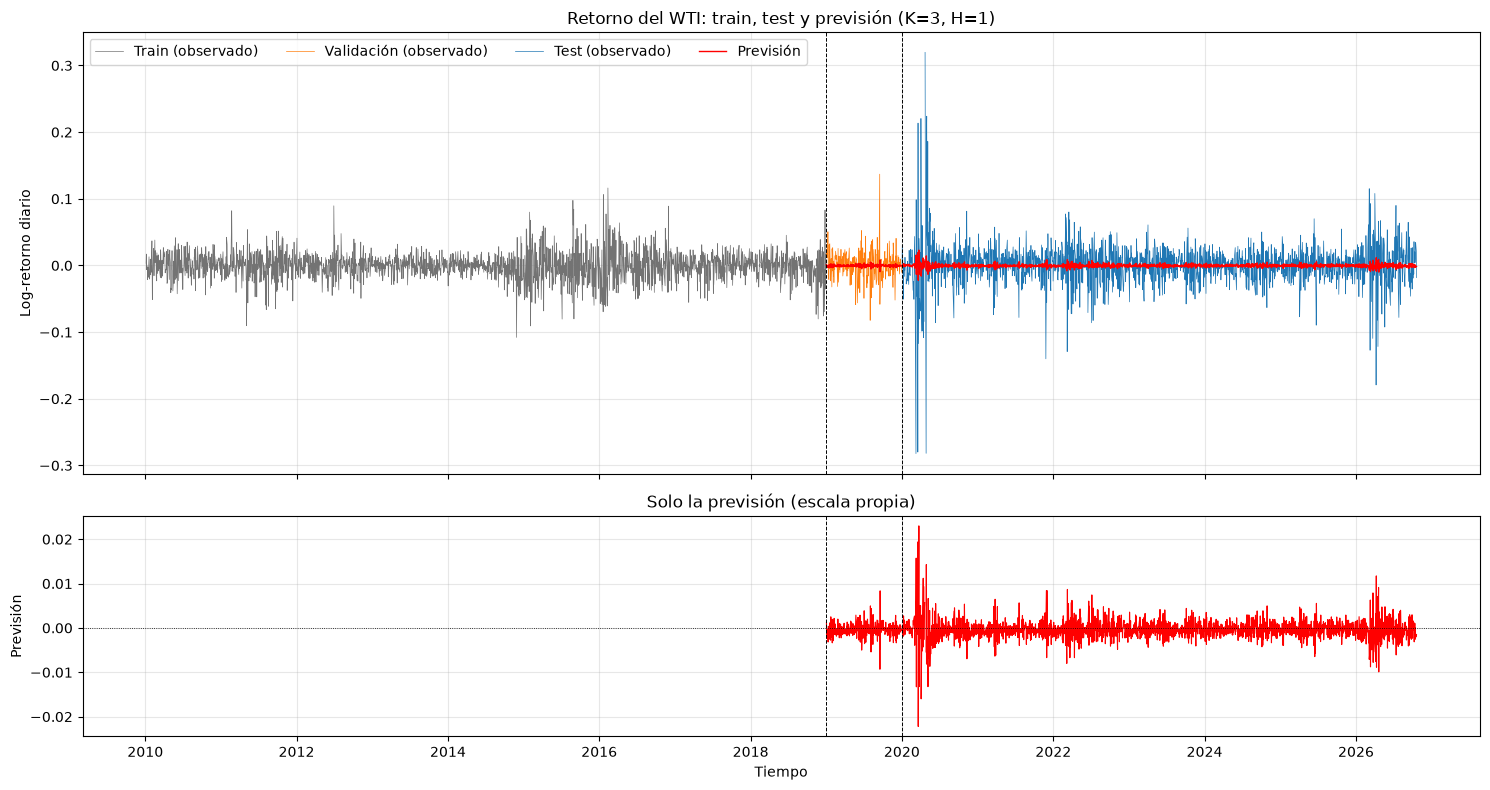

In [23]:
graficar_train_test_prediccion(y_train, y_val, y_test, pred_val, pred_test, titulo=f"(K={best_k}, H={H})")

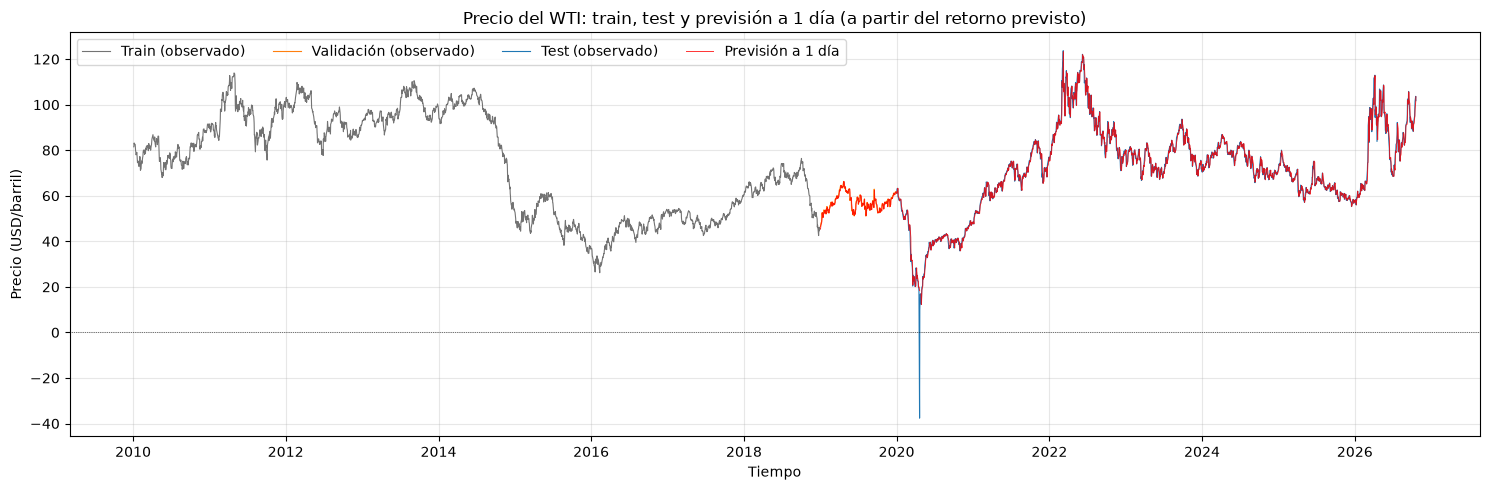

In [24]:
# Precio del WTI con la previsión a 1 día (solo H = 1). El precio negativo del 20/04/2020 se ve en el gráfico.
px_train = cargar("precios", "train")[cfg.target]
px_val = cargar("precios", "val")[cfg.target]
px_test = cargar("precios", "test", permitir_test=True)[cfg.target]
graficar_precio_prediccion(px_train, px_val, px_test, pred_val, pred_test, H=H)